## Model 2 Decision Tree

In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import FeatureUnion, make_pipeline as sk_make_pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold, GroupKFold, cross_validate
from sklearn.metrics import (make_scorer, fbeta_score, recall_score, precision_score, f1_score, accuracy_score,
                             balanced_accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score, roc_curve, get_scorer)
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict

from imblearn.pipeline import Pipeline          # imblearn Pipeline: resampling happens only on training folds
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

RANDOM_STATE = 42

## 1. Load the train/test split and define the feature sets


In [42]:
train = pd.read_csv("../results/outputs/processed_dataset_train.csv")
test  = pd.read_csv("../results/outputs/processed_dataset_test.csv")
print("train:", train.shape, " test:", test.shape)

TARGET = "next_risk_class"
NON_FEATURES = ["patient_id", "timestamp", "date", "time", "code", "code_description",
                "risk_class",           # current band - circular with glucose_mg_dl
                "next_glucose",         # the next reading itself - would leak the answer
                "daily_total_insulin",  # whole-day total - includes insulin given AFTER this reading
                "reading_index",        # position in the patient's record - not physiology (see Section 8/10 evidence)
                TARGET]

PIPELINE_PCS = [c for c in train.columns if c.startswith("PC")]   # computed with the leaky column - not used
FEATURES = [c for c in train.columns if c not in NON_FEATURES and c not in PIPELINE_PCS]
print(f"{len(FEATURES)} clean input features (pipeline PC columns excluded: {len(PIPELINE_PCS)})")
print(FEATURES)

y_train, y_test = train[TARGET], test[TARGET]
groups_train = train["patient_id"]

print("\nClass distribution (train):")
print(y_train.value_counts(normalize=True).round(3))

train: (10635, 49)  test: (2659, 49)
21 clean input features (pipeline PC columns excluded: 17)
['hour', 'is_weekend', 'glucose_mg_dl', 'prev_glucose', 'hours_since_prev', 'rolling_mean_3', 'rolling_std_3', 'insulin_regular_6h', 'insulin_nph_6h', 'insulin_ultralente_6h', 'meals_6h', 'exercise_6h', 'hypo_symptoms_6h', 'dow_sin', 'dow_cos', 'ctx_post_meal', 'ctx_pre_breakfast', 'ctx_pre_lunch', 'ctx_pre_snack', 'ctx_pre_supper', 'ctx_unspecified']

Class distribution (train):
next_risk_class
Normal           0.523
Hyperglycemic    0.361
Hypoglycemic     0.116
Name: proportion, dtype: float64


In [43]:
# Evidence for dropping daily_total_insulin: it has ONE value per patient per day, even on days with several
# readings - so a morning reading already "knows" the evening's doses.
per_day = train.groupby(["patient_id", "date"])["daily_total_insulin"].nunique()
readings = train.groupby(["patient_id", "date"]).size()
print("patient-days with a single daily_total_insulin value:", f"{(per_day == 1).mean():.1%}")
print("...of which have more than one reading that day     :", f"{(readings[per_day == 1] > 1).mean():.1%}")

patient-days with a single daily_total_insulin value: 100.0%
...of which have more than one reading that day     : 89.4%


## 2. Why a Decision Tree suits this problem

In [44]:
# Evidence that scaling is irrelevant for a tree: same tree on raw vs standardised features -> same predictions
raw_tree = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(train[FEATURES], y_train)
scaler = StandardScaler().fit(train[FEATURES])
scaled_tree = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(scaler.transform(train[FEATURES]), y_train)
same = (raw_tree.predict(test[FEATURES]) == scaled_tree.predict(scaler.transform(test[FEATURES]))).mean()
print(f"Predictions identical on {same:.1%} of test rows with and without StandardScaler (differences = floating-point ties)")

Predictions identical on 99.6% of test rows with and without StandardScaler (differences = floating-point ties)


**Is there non-linear structure for a tree to use?** Model 1 could not express that glucose relates to the classes
non-linearly. The table shows the next reading's class mix, and the **odds of hypo relative to normal**, across
fifths of `rolling_mean_3` (the average of the current and two previous glucose readings; training data only). A
straight-line (linear) term can only make these odds rise, or fall, steadily.

In [45]:
glucose_fifth = pd.qcut(train["rolling_mean_3"], 5, labels=["lowest", "low", "middle", "high", "highest"])
mix = pd.crosstab(glucose_fifth, train[TARGET], normalize="index")[["Hypoglycemic", "Normal", "Hyperglycemic"]]
mix["odds hypo : normal"] = mix["Hypoglycemic"] / mix["Normal"]
print(mix.round(3).to_string())

next_risk_class  Hypoglycemic  Normal  Hyperglycemic  odds hypo : normal
rolling_mean_3                                                          
lowest                  0.162   0.635          0.203               0.255
low                     0.115   0.652          0.234               0.176
middle                  0.103   0.522          0.375               0.197
high                    0.099   0.444          0.457               0.222
highest                 0.100   0.362          0.538               0.277


The odds of hypo relative to normal are highest at **both** ends of the glucose range and lowest just below the
middle — a U-shape. Hypo readings do not simply become more likely as glucose falls, because very high recent glucose
also carries an elevated hypo-to-normal odds. A linear term cannot represent a U-shape, which is consistent with Model 1's weak result, while a tree can split the glucose range into several bands.

## 3. Evaluation metric 

In [46]:
HYPO = "Hypoglycemic"

# Small wrappers score only the Hypoglycemic class. (Passing labels=... straight into make_scorer
# fails on string class names, because the scorer defaults to pos_label=1.)
def hypo_recall(y_true, y_pred):
    return recall_score(y_true, y_pred, labels=[HYPO], average="macro", zero_division=0)
def hypo_precision(y_true, y_pred):
    return precision_score(y_true, y_pred, labels=[HYPO], average="macro", zero_division=0)
def hypo_f2(y_true, y_pred):
    return fbeta_score(y_true, y_pred, beta=2, labels=[HYPO], average="macro", zero_division=0)

scoring = {
    "balanced_acc":   "balanced_accuracy",
    "hypo_f2":        make_scorer(hypo_f2),
    "hypo_recall":    make_scorer(hypo_recall),
    "hypo_precision": make_scorer(hypo_precision),
    "macro_f1":       "f1_macro",
    "accuracy":       "accuracy",
    "roc_auc_ovr":    "roc_auc_ovr",   # macro one-vs-rest ROC AUC from predicted probabilities
}

def test_metrics(y_true, y_pred):
    return {
        "balanced_acc":   balanced_accuracy_score(y_true, y_pred),
        "hypo_recall":    hypo_recall(y_true, y_pred),
        "hypo_precision": hypo_precision(y_true, y_pred),
        "hypo_f2":        hypo_f2(y_true, y_pred),
        "accuracy":       accuracy_score(y_true, y_pred),
        "macro_f1":       f1_score(y_true, y_pred, average="macro"),
    }

**Why not tune on hypo F2 or hypo recall?** Two trivial "models" show the problem. Predicting *every* reading as
Hypoglycemic gets hypo-recall 1.0 and a high hypo-F2, while balanced accuracy gives both trivial models exactly
0.333. Section 5 compares this trivial hypo-F2 against every trained model.

In [47]:
trivial = pd.DataFrame([
    {"model": "always Hypoglycemic", **test_metrics(y_train, np.full(len(y_train), HYPO))},
    {"model": "always Normal",       **test_metrics(y_train, np.full(len(y_train), "Normal"))},
]).round(3)
TRIVIAL_HYPO_F2 = trivial.loc[0, "hypo_f2"]
print(trivial.to_string())

                 model  balanced_acc  hypo_recall  hypo_precision  hypo_f2  accuracy  macro_f1
0  always Hypoglycemic         0.333          1.0           0.116    0.396     0.116     0.069
1        always Normal         0.333          0.0           0.000    0.000     0.523     0.229


## 4. Hyperparameter tuning — GridSearchCV

In [48]:
# StandardScaler -> PCA(95% variance). imblearn does not allow a Pipeline as an intermediate step,
# so the block is wrapped in a FeatureUnion (which imblearn accepts).
def pca_block():
    return sk_make_pipeline(StandardScaler(), PCA(n_components=0.95, random_state=RANDOM_STATE))

FEATURE_OPTIONS = {
    "original": "passthrough",
    "pca":      FeatureUnion([("pcs", pca_block())]),
    "all":      FeatureUnion([("original", "passthrough"), ("pcs", pca_block())]),
}

pipe = Pipeline([
    ("features", "passthrough"),
    ("sampler",  "passthrough"),
    ("clf",      DecisionTreeClassifier(random_state=RANDOM_STATE)),
])

TREE_GRID = {"clf__max_depth":        [1, 2, 3, 5, 7, 10, None],
             "clf__min_samples_leaf": [1, 10, 50],
             "clf__criterion":        ["gini", "entropy"]}
common = {"features": list(FEATURE_OPTIONS.values()), **TREE_GRID}
param_grid = [
    {**common, "sampler": ["passthrough"], "clf__class_weight": [None, "balanced"]},
    {**common, "sampler": [SMOTE(random_state=RANDOM_STATE), RandomUnderSampler(random_state=RANDOM_STATE)],
     "clf__class_weight": [None]},
]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

gs = GridSearchCV(pipe, param_grid, scoring=scoring, refit="balanced_acc", cv=cv, n_jobs=-1,
                  return_train_score=True,   # training-fold scores, for the overfitting check
                  error_score="raise")       # fail loudly instead of silently returning NaN
gs.fit(train[FEATURES], y_train)

def feature_set_name(step):
    if isinstance(step, str): return "original"
    return "all" if len(step.transformer_list) == 2 else "pca"

cv_all = pd.DataFrame(gs.cv_results_)
cv_all["feature_set"] = cv_all["param_features"].apply(feature_set_name)
print(cv_all.groupby("feature_set")["mean_test_balanced_acc"].max().round(3).rename("best CV balanced acc"))
print("\nTotal configurations evaluated:", len(cv_all))

c:\Users\pc\AppData\Local\Programs\Python\Python310\lib\site-packages\joblib\externals\loky\process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


feature_set
all         0.484
original    0.482
pca         0.474
Name: best CV balanced acc, dtype: float64

Total configurations evaluated: 504


## 5. Comparison across varieties (cross-validation, training set)
Each row below is one **variety** = feature set × imbalance strategy, shown with its best `max_depth`,
`min_samples_leaf` and `criterion` (12 varieties, each tuned over 42 tree settings).

In [49]:
def strategy(sampler, class_weight):
    if isinstance(sampler, SMOTE): return "SMOTE"
    if isinstance(sampler, RandomUnderSampler): return "Undersampling"
    return "Class weights" if class_weight == "balanced" else "None"

cv_all["imbalance"] = [strategy(s, w) for s, w in zip(cv_all["param_sampler"], cv_all["param_clf__class_weight"])]
cv_all["depth"] = cv_all["param_clf__max_depth"].apply(lambda d: np.inf if pd.isna(d) else float(d))
cv_all["depth_label"] = cv_all["depth"].apply(lambda d: "unlimited" if np.isinf(d) else str(int(d)))
cv_all["leaf"] = cv_all["param_clf__min_samples_leaf"].astype(int)
cv_all["criterion"] = cv_all["param_clf__criterion"]

metric_cols = ["mean_test_balanced_acc", "std_test_balanced_acc", "mean_test_hypo_f2", "mean_test_hypo_recall",
               "mean_test_hypo_precision", "mean_test_macro_f1", "mean_test_accuracy", "mean_test_roc_auc_ovr"]
best_per_variety = (cv_all.sort_values("mean_test_balanced_acc", ascending=False)
                          .groupby(["feature_set", "imbalance"], as_index=False).first())
varieties = (best_per_variety[["feature_set", "imbalance", "depth_label", "leaf", "criterion"] + metric_cols]
             .rename(columns=lambda c: c.replace("mean_test_", ""))
             .sort_values("balanced_acc", ascending=False).reset_index(drop=True))
print(f"{len(varieties)} varieties (each tuned over {cv_all.groupby(['feature_set', 'imbalance']).size().iloc[0]} tree settings)")
print(varieties.round(3).to_string())

12 varieties (each tuned over 42 tree settings)
   feature_set      imbalance depth_label  leaf criterion  balanced_acc  std_test_balanced_acc  hypo_f2  hypo_recall  hypo_precision  macro_f1  accuracy  roc_auc_ovr
0          all  Class weights           7     1   entropy         0.484                  0.013    0.387        0.522           0.191     0.432     0.459        0.643
1     original  Undersampling           5    50      gini         0.482                  0.019    0.382        0.519           0.186     0.428     0.455        0.651
2     original  Class weights           7    50      gini         0.480                  0.013    0.372        0.491           0.189     0.435     0.466        0.658
3     original          SMOTE           7     1      gini         0.479                  0.014    0.348        0.434           0.199     0.445     0.485        0.654
4          all  Undersampling           7    50   entropy         0.478                  0.013    0.386        0.536      

In [50]:
# Effect of each choice, averaged over the other settings (best tree settings per variety)
# (the feature-set comparison uses only varieties that handle imbalance - the "None" rows never predict
#  Hypoglycemic, so they would just drag every average down equally)
cols_show = ["balanced_acc", "hypo_recall", "hypo_precision", "hypo_f2", "macro_f1", "accuracy"]
handled = varieties[varieties.imbalance != "None"]
print(varieties.groupby("imbalance")[cols_show].mean().round(3).sort_values("balanced_acc", ascending=False), "\n")
print(handled.groupby("feature_set")[cols_show].mean().round(3).sort_values("balanced_acc", ascending=False), "\n")

print(f"Trivial 'always Hypoglycemic' hypo-F2 : {TRIVIAL_HYPO_F2:.3f}")
print(f"Best hypo-F2 of any trained model     : {cv_all['mean_test_hypo_f2'].max():.3f}")
print("-> tuning on hypo-F2 would have rewarded the trivial model over every real one"
      if TRIVIAL_HYPO_F2 > cv_all['mean_test_hypo_f2'].max() else
      "-> here the best trained model edges past the trivial one, but only just")

               balanced_acc  hypo_recall  hypo_precision  hypo_f2  macro_f1  \
imbalance                                                                     
Class weights         0.479        0.510           0.188    0.379     0.428   
SMOTE                 0.474        0.482           0.189    0.361     0.429   
Undersampling         0.473        0.512           0.184    0.376     0.421   
None                  0.452        0.259           0.240    0.255     0.451   

               accuracy  
imbalance                
Class weights     0.456  
SMOTE             0.462  
Undersampling     0.448  
None              0.525   

             balanced_acc  hypo_recall  hypo_precision  hypo_f2  macro_f1  \
feature_set                                                                 
original            0.480        0.481           0.192    0.367     0.436   
all                 0.477        0.498           0.189    0.373     0.429   
pca                 0.469        0.525           0.181    0

## 6. Choosing the model


In [51]:
N_FOLDS = cv.get_n_splits()
cv_all["se_bal"] = cv_all["std_test_balanced_acc"] / np.sqrt(N_FOLDS)
top = cv_all.loc[cv_all["mean_test_balanced_acc"].idxmax()]
threshold = top["mean_test_balanced_acc"] - top["se_bal"]

IMB_RANK  = {"Class weights": 0, "Undersampling": 1, "SMOTE": 2, "None": 3}
FS_RANK   = {"original": 0, "pca": 1, "all": 2}
CRIT_RANK = {"gini": 0, "entropy": 1}

tied = cv_all[cv_all["mean_test_balanced_acc"] >= threshold].copy()
tied["rank"] = list(zip(tied.imbalance.map(IMB_RANK), tied.feature_set.map(FS_RANK), tied.depth, -tied.leaf,
                        tied.criterion.map(CRIT_RANK), -tied.mean_test_balanced_acc))
chosen = tied.sort_values("rank").iloc[0]

def describe(r):
    return (f"{r.feature_set} features, {r.imbalance}, max_depth={r.depth_label}, "
            f"min_samples_leaf={r.leaf}, criterion={r.criterion}")

print(f"Highest CV balanced acc : {top.mean_test_balanced_acc:.4f}  ({describe(top)})")
print(f"One-SE threshold        : {threshold:.4f}   -> {len(tied)} of {len(cv_all)} configurations within one standard error of the best")
print(f"Chosen (first by preference)  : {chosen.mean_test_balanced_acc:.4f} ± {chosen.std_test_balanced_acc:.4f}  ({describe(chosen)})")

print("\nTied configurations by max_depth (how deep do tied trees go?):")
print(tied.groupby("depth_label").size().reindex(["1", "2", "3", "5", "7", "10", "unlimited"]).dropna().astype(int).to_string())

Highest CV balanced acc : 0.4836  (all features, Class weights, max_depth=7, min_samples_leaf=1, criterion=entropy)
One-SE threshold        : 0.4777   -> 18 of 504 configurations within one standard error of the best
Chosen (first by preference)  : 0.4802 ± 0.0125  (original features, Class weights, max_depth=7, min_samples_leaf=50, criterion=gini)

Tied configurations by max_depth (how deep do tied trees go?):
depth_label
5            5
7            9
10           3
unlimited    1


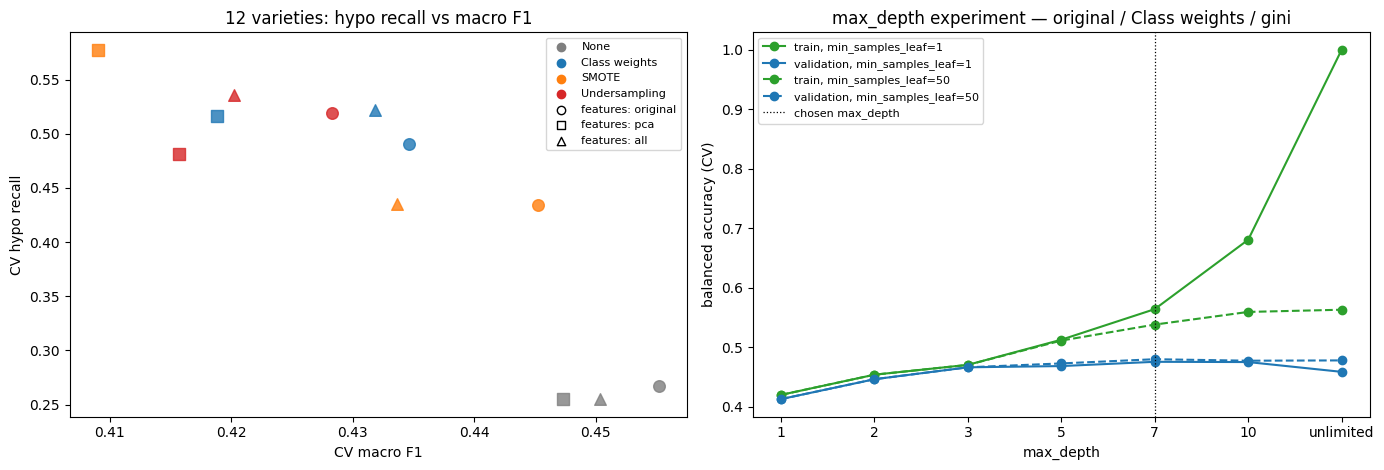

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# (a) hypo-recall vs macro-F1 for every variety - the trade-off the imbalance strategies create
markers = {"original": "o", "pca": "s", "all": "^"}
colors = {"None": "tab:gray", "Class weights": "tab:blue", "SMOTE": "tab:orange", "Undersampling": "tab:red"}
for _, r in varieties.iterrows():
    axes[0].scatter(r.macro_f1, r.hypo_recall, marker=markers[r.feature_set], color=colors[r.imbalance],
                    s=70, alpha=0.8)
for k, c in colors.items():
    axes[0].scatter([], [], color=c, label=k)
for k, m in markers.items():
    axes[0].scatter([], [], marker=m, color="white", edgecolor="black", label=f"features: {k}")
axes[0].set_xlabel("CV macro F1"); axes[0].set_ylabel("CV hypo recall")
axes[0].set_title(f"{len(varieties)} varieties: hypo recall vs macro F1")
axes[0].legend(fontsize=8, loc="best")

# (b) max_depth experiment: train vs validation balanced accuracy, chosen feature set / imbalance / criterion
DEPTHS = ["1", "2", "3", "5", "7", "10", "unlimited"]
base = cv_all[(cv_all.feature_set == chosen.feature_set) & (cv_all.imbalance == chosen.imbalance) &
              (cv_all.criterion == chosen.criterion)]
for leaf, style in [(1, "-"), (int(chosen.leaf), "--")]:
    if leaf == 1 and style == "--": continue
    sub = base[base.leaf == leaf].set_index("depth_label").reindex(DEPTHS)
    x = range(len(DEPTHS))
    axes[1].plot(x, sub.mean_train_balanced_acc, style, marker="o", color="tab:green",
                 label=f"train, min_samples_leaf={leaf}")
    axes[1].plot(x, sub.mean_test_balanced_acc, style, marker="o", color="tab:blue",
                 label=f"validation, min_samples_leaf={leaf}")
axes[1].axvline(DEPTHS.index(chosen.depth_label), color="black", ls=":", lw=0.9, label="chosen max_depth")
axes[1].set_xticks(range(len(DEPTHS))); axes[1].set_xticklabels(DEPTHS)
axes[1].set_xlabel("max_depth"); axes[1].set_ylabel("balanced accuracy (CV)")
axes[1].set_title(f"max_depth experiment — {chosen.feature_set} / {chosen.imbalance} / {chosen.criterion}")
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 7. Final model — refit on the full training set, evaluated once on the test set
The chosen configuration is rebuilt from its parameters, refit on all training rows, and evaluated on the test set.

Final model: original features, Class weights, max_depth=7, min_samples_leaf=50, criterion=gini
Fitted tree: depth = 7, leaves = 76

               precision    recall  f1-score   support

Hyperglycemic      0.532     0.507     0.519       960
 Hypoglycemic      0.180     0.565     0.273       308
       Normal      0.686     0.382     0.491      1391

     accuracy                          0.449      2659
    macro avg      0.466     0.485     0.428      2659
 weighted avg      0.571     0.449     0.476      2659



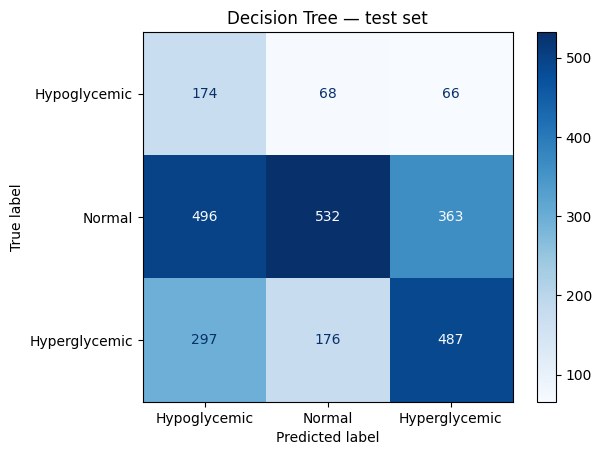

In [53]:
chosen_params = cv_all.loc[chosen.name, "params"]
final_model = clone(pipe).set_params(**chosen_params).fit(train[FEATURES], y_train)
tree = final_model.named_steps["clf"]
print("Final model:", describe(chosen))
print(f"Fitted tree: depth = {tree.get_depth()}, leaves = {tree.get_n_leaves()}")

y_pred = final_model.predict(test[FEATURES])
print("\n" + classification_report(y_test, y_pred, digits=3))

LABELS = ["Hypoglycemic", "Normal", "Hyperglycemic"]
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=LABELS), display_labels=LABELS).plot(cmap="Blues")
plt.title("Decision Tree — test set"); plt.show()

In [54]:
final_row = {"model": "Decision Tree (tuned, chosen)", **test_metrics(y_test, y_pred)}

# Untuned tree: scikit-learn defaults (fully grown), same 21 features, no imbalance handling
default_tree = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(train[FEATURES], y_train)
default_row = {"model": "Decision Tree (untuned defaults)", **test_metrics(y_test, default_tree.predict(test[FEATURES]))}
print(f"Untuned tree: depth = {default_tree.get_depth()}, leaves = {default_tree.get_n_leaves()}")

rows = [default_row, final_row]
try:   # Model 1's saved result, trained under the same protocol and scored on the same test set
    lr = pd.read_csv("../results/outputs/model_results_logistic_regression.csv").iloc[0]
    rows.append({"model": "Logistic Regression (Model 1, tuned)",
                 **{m: lr[m] for m in ["balanced_acc", "hypo_recall", "hypo_precision", "hypo_f2", "accuracy", "macro_f1"]}})
except FileNotFoundError:
    print("(Model 1 results file not found - run the Model 1 notebook to add its row to this table.)")

comparison = pd.DataFrame(rows)
print(comparison[["model", "balanced_acc", "hypo_recall", "hypo_precision", "hypo_f2", "accuracy", "macro_f1"]]
      .round(3).to_string(index=False))

Untuned tree: depth = 34, leaves = 3021
                               model  balanced_acc  hypo_recall  hypo_precision  hypo_f2  accuracy  macro_f1
    Decision Tree (untuned defaults)         0.463        0.263           0.255    0.261     0.536     0.462
       Decision Tree (tuned, chosen)         0.485        0.565           0.180    0.396     0.449     0.428
Logistic Regression (Model 1, tuned)         0.478        0.519           0.182    0.379     0.461     0.433


In [55]:
# What the hypo precision means in practice on the test set
n_alarms = int((y_pred == HYPO).sum())
n_true = int(((y_pred == HYPO) & (y_test == HYPO)).sum())
base_rate = (y_test == HYPO).mean()
alarm = {
    "hypo alarms raised":             n_alarms,
    "share of all readings flagged":  f"{n_alarms / len(y_test):.1%}",
    "real hypo events caught":        f"{n_true} of {int((y_test == HYPO).sum())}",
    "false alarms per real hypo":     f"{(n_alarms - n_true) / max(n_true, 1):.1f}",
    "precision vs base rate (lift)":  f"{(n_true / max(n_alarms, 1)) / base_rate:.2f}x",
}
print(pd.Series(alarm, name="value").to_frame().to_string())

                                    value
hypo alarms raised                    967
share of all readings flagged       36.4%
real hypo events caught        174 of 308
false alarms per real hypo            4.6
precision vs base rate (lift)       1.55x


### ROC AUC — ranking quality, independent of the threshold
Precision and recall above depend on the default rule "predict the majority class of the leaf". ROC AUC instead asks
how well the predicted probabilities *rank* readings. A tree's probabilities are the class proportions inside each
leaf, so a tree with few leaves can only produce a few distinct scores and its ROC curve is coarse. Each curve is one
class against the other two.

Test ROC AUC - Hypoglycemic vs rest : 0.655


Test ROC AUC - macro one-vs-rest    : 0.656
Distinct hypo probability values the tree can output: 72


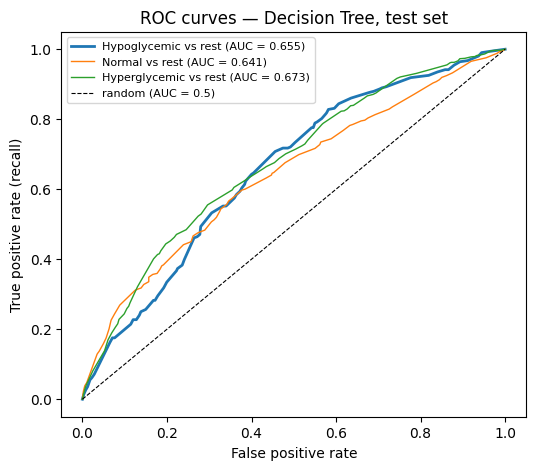

In [56]:
proba = final_model.predict_proba(test[FEATURES])
classes = list(final_model.named_steps["clf"].classes_)
hypo_auc  = roc_auc_score((y_test == HYPO).astype(int), proba[:, classes.index(HYPO)])
macro_auc = roc_auc_score(y_test, proba, multi_class="ovr", average="macro", labels=classes)
print(f"Test ROC AUC - Hypoglycemic vs rest : {hypo_auc:.3f}")
print(f"Test ROC AUC - macro one-vs-rest    : {macro_auc:.3f}")
print(f"Distinct hypo probability values the tree can output: {len(np.unique(proba[:, classes.index(HYPO)]))}")

plt.figure(figsize=(6, 5))
for c in LABELS:
    fpr, tpr, _ = roc_curve((y_test == c).astype(int), proba[:, classes.index(c)])
    auc_c = roc_auc_score((y_test == c).astype(int), proba[:, classes.index(c)])
    plt.plot(fpr, tpr, label=f"{c} vs rest (AUC = {auc_c:.3f})", lw=2 if c == HYPO else 1)
plt.plot([0, 1], [0, 1], "k--", lw=0.8, label="random (AUC = 0.5)")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate (recall)")
plt.title("ROC curves — Decision Tree, test set"); plt.legend(fontsize=8); plt.show()

### Choosing the hypo alarm threshold on training data
The default rule (predict the class with the highest probability or score) is not tuned for catching hypo events. Here the
alarm threshold is chosen from **out-of-fold** hypo scores on the **training set only** — the test set plays no part in
choosing it — for three recall targets, and each resulting rule is applied to the test set once. Which recall level is
acceptable is a clinical decision; the targets only show the trade-off between caught hypo events and false alarms.

In [57]:
score_method = "predict_proba" if hasattr(final_model, "predict_proba") else "decision_function"
hypo_col = list(final_model.classes_).index(HYPO)
oof_scores = cross_val_predict(clone(final_model), train[FEATURES], y_train, cv=cv, method=score_method)[:, hypo_col]
test_hypo_scores = getattr(final_model, score_method)(test[FEATURES])[:, hypo_col]
oof_is_hypo = (y_train == HYPO).values
test_is_hypo = (y_test == HYPO).values

default_flag = (y_pred == HYPO)
rows = [{"rule": "default (highest score wins)", "threshold": np.nan,
         "test hypo recall": test_is_hypo[default_flag].sum() / test_is_hypo.sum(),
         "test hypo precision": test_is_hypo[default_flag].sum() / max(default_flag.sum(), 1),
         "test share flagged": default_flag.mean()}]
order = np.argsort(-oof_scores)
cum_recall = np.cumsum(oof_is_hypo[order]) / oof_is_hypo.sum()
for target in [0.5, 0.6, 0.7]:
    tau = oof_scores[order][np.searchsorted(cum_recall, target)]
    flag = test_hypo_scores >= tau
    rows.append({"rule": f"threshold for out-of-fold recall {target}", "threshold": tau,
                 "test hypo recall": test_is_hypo[flag].sum() / test_is_hypo.sum(),
                 "test hypo precision": test_is_hypo[flag].sum() / max(flag.sum(), 1),
                 "test share flagged": flag.mean()})
threshold_table = pd.DataFrame(rows)
print(threshold_table.round(3).to_string(index=False))
threshold_table.assign(model=final_row["model"]).to_csv(
    "../results/outputs/threshold_analysis_" + str(final_row["model"]).split()[0].lower() + ".csv", index=False)

                                rule  threshold  test hypo recall  test hypo precision  test share flagged
        default (highest score wins)        NaN             0.565                0.180               0.364
threshold for out-of-fold recall 0.5      0.371             0.552                0.175               0.364
threshold for out-of-fold recall 0.6      0.335             0.584                0.174               0.390
threshold for out-of-fold recall 0.7      0.267             0.718                0.165               0.502


## 8. Inside the tree — structure, rules and feature importance


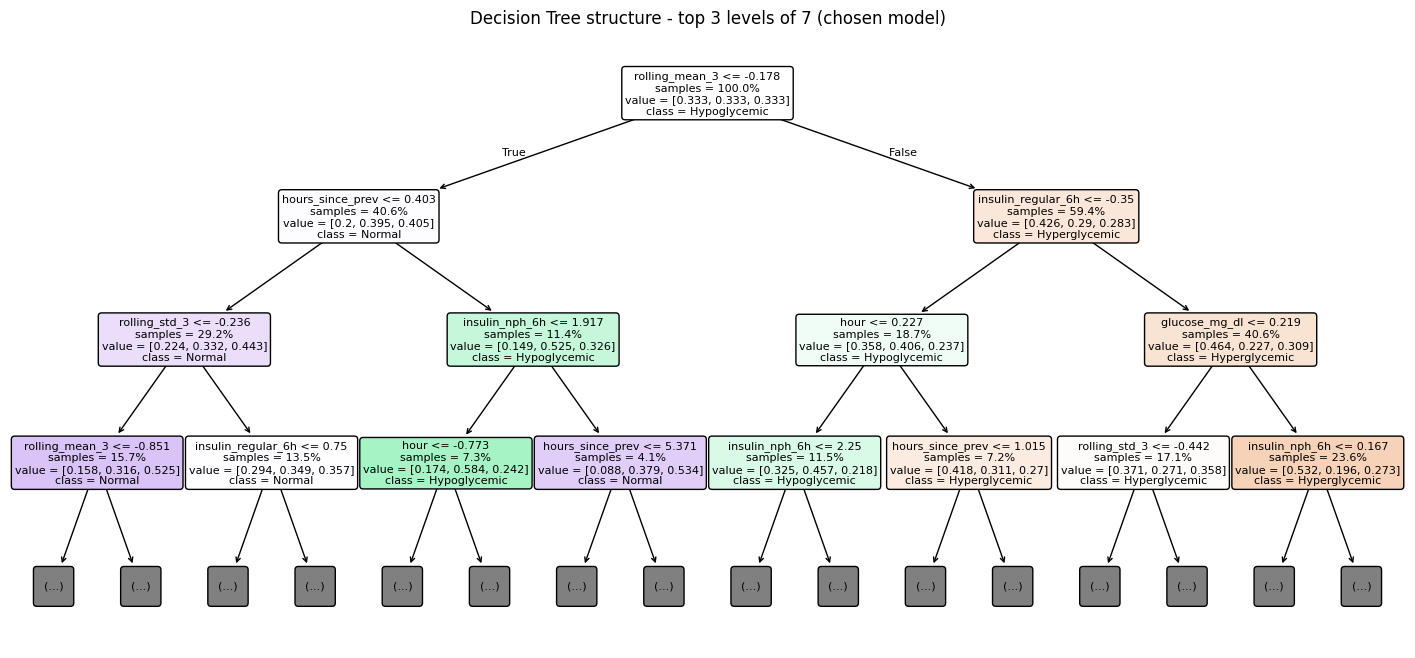

|--- rolling_mean_3 <= -0.18
|   |--- hours_since_prev <= 0.40
|   |   |--- rolling_std_3 <= -0.24
|   |   |   |--- rolling_mean_3 <= -0.85
|   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- rolling_mean_3 >  -0.85
|   |   |   |   |--- truncated branch of depth 4
|   |   |--- rolling_std_3 >  -0.24
|   |   |   |--- insulin_regular_6h <= 0.75
|   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- insulin_regular_6h >  0.75
|   |   |   |   |--- truncated branch of depth 2
|   |--- hours_since_prev >  0.40
|   |   |--- insulin_nph_6h <= 1.92
|   |   |   |--- hour <= -0.77
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- hour >  -0.77
|   |   |   |   |--- truncated branch of depth 4
|   |   |--- insulin_nph_6h >  1.92
|   |   |   |--- hours_since_prev <= 5.37
|   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- hours_since_prev >  5.37
|   |   |   |   |--- class: Normal
|--- rolling_mean_3 >  -0.18
|   |--- insulin_regular_6h <= -0.35

In [58]:
def feature_names(model):
    fs = feature_set_name(model.named_steps["features"])
    if fs == "original":
        return FEATURES
    n_pc = model.named_steps["features"].transformer_list[-1][1].named_steps["pca"].n_components_
    pcs = [f"PC{i + 1}" for i in range(n_pc)]
    return pcs if fs == "pca" else FEATURES + pcs

names = feature_names(final_model)
plt.figure(figsize=(18, 8))
plot_tree(tree, max_depth=3, feature_names=names, class_names=list(tree.classes_), filled=True, rounded=True,
          fontsize=8, proportion=True, impurity=False)
plt.title(f"Decision Tree structure - top 3 levels of {tree.get_depth()} (chosen model)"); plt.show()

print(export_text(tree, feature_names=names, max_depth=3, decimals=2))

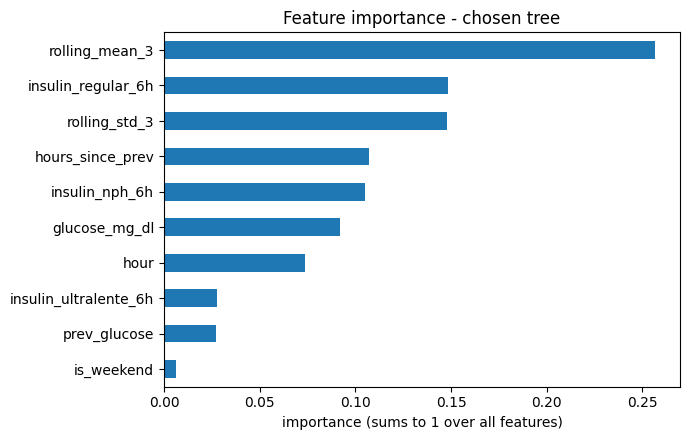

Features used by the tree: 12 of 21
rolling_mean_3           0.257
insulin_regular_6h       0.148
rolling_std_3            0.148
hours_since_prev         0.107
insulin_nph_6h           0.105
glucose_mg_dl            0.092
hour                     0.074
insulin_ultralente_6h    0.028
prev_glucose             0.027
is_weekend               0.006


In [59]:
imp = pd.Series(tree.feature_importances_, index=names).sort_values(ascending=False)
top_imp = imp[imp > 0].head(10)
top_imp[::-1].plot.barh(figsize=(7, 4.5), color="tab:blue")
plt.xlabel("importance (sums to 1 over all features)"); plt.title("Feature importance - chosen tree")
plt.tight_layout(); plt.show()
print(f"Features used by the tree: {int((imp > 0).sum())} of {len(imp)}")
print(top_imp.round(3).to_string())

In [60]:
# Stability: refit the chosen configuration on 30 bootstrap resamples; how often is each feature in the top 3?
rng = np.random.RandomState(RANDOM_STATE)
N_BOOT = 30
top3_count = pd.Series(0.0, index=names)
root_feature = []
for _ in range(N_BOOT):
    idx = rng.choice(len(train), len(train), replace=True)
    boot = clone(final_model).fit(train[FEATURES].iloc[idx], y_train.iloc[idx])
    bnames = feature_names(boot)
    bt = boot.named_steps["clf"]
    b_imp = pd.Series(bt.feature_importances_, index=bnames).sort_values(ascending=False)
    for f in b_imp.head(3).index:
        if f in top3_count.index: top3_count[f] += 1
    root_feature.append(bnames[bt.tree_.feature[0]] if bt.tree_.node_count > 1 else "(no split)")
top3_share = (top3_count / N_BOOT).sort_values(ascending=False)
root_share = pd.Series(root_feature).value_counts(normalize=True)
final_root = names[tree.tree_.feature[0]] if tree.tree_.node_count > 1 else "(no split)"
print(f"Share of {N_BOOT} bootstrap trees with the feature in their top 3 importances:")
print(top3_share.head(8).round(2).to_string())
print(f"\nRoot split of the final tree: {final_root}")
print(f"Share of bootstrap trees with the same root feature: {root_share.get(final_root, 0):.0%}")

Share of 30 bootstrap trees with the feature in their top 3 importances:
rolling_mean_3        1.00
rolling_std_3         0.73
insulin_regular_6h    0.67
hours_since_prev      0.37
glucose_mg_dl         0.17
hour                  0.07
is_weekend            0.00
prev_glucose          0.00

Root split of the final tree: rolling_mean_3
Share of bootstrap trees with the same root feature: 100%


In [61]:
ordered_ev = train.assign(ts=pd.to_datetime(train["timestamp"])).sort_values(["patient_id", "ts", "reading_index"])
n_ev = ordered_ev.groupby("patient_id")["patient_id"].transform("size")
ordered_ev["own_position"] = ordered_ev.groupby("patient_id").cumcount() / n_ev
ordered_ev["hypo_next"] = (ordered_ev[TARGET] == HYPO).astype(int)
ordered_ev["own_fifth"] = pd.cut(ordered_ev["own_position"], [0, 0.2, 0.4, 0.6, 0.8, 1.0], right=False,
                                 labels=["1st", "2nd", "3rd", "4th", "5th"])
print("WITHIN patients: share of readings whose NEXT reading is hypoglycemic, by fifth of that patient's own record")
print(ordered_ev.groupby("own_fifth", observed=True)["hypo_next"].mean().round(3).to_string())

per_patient = ordered_ev.groupby("patient_id").agg(readings=("hypo_next", "size"), hypo_share=("hypo_next", "mean"),
                                                   highest_index=("reading_index", "max"))
per_patient["record length"] = pd.qcut(per_patient["readings"], 3, labels=["short", "medium", "long"])
print("\nBETWEEN patients: by length of the patient's record")
print(per_patient.groupby("record length", observed=True).agg(
    patients=("readings", "size"), mean_readings=("readings", "mean"), hypo_share=("hypo_share", "mean"),
    mean_highest_reading_index=("highest_index", "mean")).round(3).to_string())

WITHIN patients: share of readings whose NEXT reading is hypoglycemic, by fifth of that patient's own record
own_fifth
1st    0.125
2nd    0.122
3rd    0.123
4th    0.102
5th    0.108

BETWEEN patients: by length of the patient's record
               patients  mean_readings  hypo_share  mean_highest_reading_index
record length                                                                 
short                24         66.833       0.179                      -0.089
medium               23         98.000       0.128                       0.104
long                 23        294.652       0.121                       1.427


## 9. Overfitting check — training vs cross-validation vs test
A Decision Tree is the classic overfitter: left to grow, it ends with a leaf for almost every training reading and
scores ~100% on the data it has seen. Three scores are compared for the chosen configuration:
- **Train (in-fold):** average score on the training folds during cross-validation (data the model was fit on).
- **CV (validation):** average score on the held-out folds.
- **Test:** the final model on the test set.

A large train-vs-CV gap means overfitting. The same comparison is made for the **untuned, fully grown** tree, to show
what the tuning (depth and leaf size) bought. The depth experiment in Section 6 shows how the gap opens as the tree
gets deeper.

In [62]:
fit_rows = ["balanced_acc", "hypo_recall", "macro_f1", "roc_auc_ovr"]
test_scores = {**test_metrics(y_test, y_pred), "roc_auc_ovr": macro_auc}
overfit = pd.DataFrame({
    "Train (in-fold)":  {m: chosen[f"mean_train_{m}"] for m in fit_rows},
    "CV (validation)":  {m: chosen[f"mean_test_{m}"] for m in fit_rows},
    "Test":             {m: test_scores[m] for m in fit_rows},
})
overfit["train - CV gap"] = overfit["Train (in-fold)"] - overfit["CV (validation)"]
print("Chosen (tuned) tree:")
print(overfit.round(3).to_string())

# Untuned, fully grown tree: same folds, same scorers
u = cross_validate(clone(default_tree), train[FEATURES], y_train, cv=cv, scoring=scoring, return_train_score=True)
default_test = {**test_metrics(y_test, default_tree.predict(test[FEATURES])),
                "roc_auc_ovr": roc_auc_score(y_test, default_tree.predict_proba(test[FEATURES]),
                                             multi_class="ovr", average="macro", labels=list(default_tree.classes_))}
overfit_default = pd.DataFrame({
    "Train (in-fold)":  {m: u[f"train_{m}"].mean() for m in fit_rows},
    "CV (validation)":  {m: u[f"test_{m}"].mean() for m in fit_rows},
    "Test":             {m: default_test[m] for m in fit_rows},
})
overfit_default["train - CV gap"] = overfit_default["Train (in-fold)"] - overfit_default["CV (validation)"]
print("\nUntuned, fully grown tree (defaults):")
print(overfit_default.round(3).to_string())

Chosen (tuned) tree:
              Train (in-fold)  CV (validation)   Test  train - CV gap
balanced_acc            0.538            0.480  0.485           0.058
hypo_recall             0.616            0.491  0.565           0.125
macro_f1                0.475            0.435  0.428           0.040
roc_auc_ovr             0.713            0.658  0.656           0.055

Untuned, fully grown tree (defaults):
              Train (in-fold)  CV (validation)   Test  train - CV gap
balanced_acc              1.0            0.452  0.463           0.548
hypo_recall               1.0            0.259  0.263           0.741
macro_f1                  1.0            0.451  0.462           0.549
roc_auc_ovr               1.0            0.590  0.599           0.410


## 10. Validation checks — does the row-wise split flatter the scores?


In [63]:
# (a) Time-ordered: each patient's first 80% of readings train, last 20% validate
ordered = train.assign(ts=pd.to_datetime(train["timestamp"])).sort_values(["patient_id", "ts", "reading_index"])
position = ordered.groupby("patient_id").cumcount()
n_readings = ordered.groupby("patient_id")["patient_id"].transform("size")
is_late = position >= np.floor(n_readings * 0.8)
early, late = ordered[~is_late], ordered[is_late]
print(f"Time-ordered split: {len(early)} earlier readings train / {len(late)} later readings validate "
      f"({late.patient_id.nunique()} patients in both)")
print(pd.DataFrame({"earlier 80%": early[TARGET].value_counts(normalize=True),
                    "later 20%":   late[TARGET].value_counts(normalize=True)}).round(3), "\n")

time_model = clone(final_model).fit(early[FEATURES], early[TARGET])
scorers = {m: (get_scorer(v) if isinstance(v, str) else v) for m, v in scoring.items()}
time_scores = {m: scorers[m](time_model, late[FEATURES], late[TARGET]) for m in scoring}

# (b) Unseen-patient generalisation check: GroupKFold, validation patients never seen in training
group_cv = cross_validate(clone(final_model), train[FEATURES], y_train, groups=groups_train,
                          cv=GroupKFold(n_splits=5), scoring=scoring)

check = pd.DataFrame({
    "Row-wise CV (used for tuning)":     {m: chosen[f"mean_test_{m}"] for m in scoring},
    "Time-ordered (monitored patients)": time_scores,
    "GroupKFold (unseen patients)":      {m: group_cv[f"test_{m}"].mean() for m in scoring},
})
check["time-ordered - row-wise"] = check["Time-ordered (monitored patients)"] - check["Row-wise CV (used for tuning)"]
check["unseen patients - row-wise"] = check["GroupKFold (unseen patients)"] - check["Row-wise CV (used for tuning)"]
print(check.round(3).to_string())

Time-ordered split: 8477 earlier readings train / 2158 later readings validate (70 patients in both)
                 earlier 80%  later 20%
next_risk_class                        
Normal                 0.519      0.540
Hyperglycemic          0.363      0.351
Hypoglycemic           0.117      0.109 

                Row-wise CV (used for tuning)  Time-ordered (monitored patients)  GroupKFold (unseen patients)  time-ordered - row-wise  unseen patients - row-wise
balanced_acc                            0.480                              0.514                         0.454                    0.034                      -0.026
hypo_f2                                 0.372                              0.404                         0.367                    0.032                      -0.005
hypo_recall                             0.491                              0.566                         0.535                    0.075                       0.045
hypo_precision                          0

## 11. Conclusion, limitations and improvements

**What mattered:**
1. **Controlling the tree's size mattered most.** The untuned, fully grown tree (depth 34, 3,021 leaves) scores 1.000 on its training folds but only 0.452 on held-out folds, and it catches only about a quarter of the hypo events. The chosen tree (depth 7, 76 leaves, at least 50 readings per leaf) has a train − CV gap of 0.058 and catches 56.5% of hypo events on the test set. The competitive configurations include depths 5, 7, 10 and unlimited, so beyond about five levels a deeper tree does not do better within the noise.
2. **Imbalance handling helped, but less than for the linear model.** Without it the tree still predicts some hypo readings (recall 0.259), because a tree can isolate small groups; with any of the three strategies balanced accuracy rises by about 0.02–0.03. Class weights scored highest of the three by a small margin (the spread among them, 0.005, is inside the fold-to-fold noise).
3. **The feature set made little difference.** The original features (0.480), all features (0.477) and PCA only (0.469) differ by about as much as the fold-to-fold standard deviation (0.011). The original features are enough, and they keep the rules readable.
4. **No clear gain over the linear baseline.** Test balanced accuracy is 0.485 against Logistic Regression's 0.478, and macro ROC AUC 0.656 against 0.652; both differences are inside the noise. The tree's higher hypo recall (0.565 against 0.519) comes with more readings flagged (36.4% against 33.0%) at about the same precision (0.180 against 0.182): a different operating point, not better ranking.
5. **Coarse scores limit the ranking quality.** The tree can output only 72 distinct hypo probabilities, because each leaf predicts with the class mix of the readings inside it. That keeps ROC AUC modest and makes the alarm thresholds in Section 7 move in steps.

**Reading the tree:**
- The first split is on recent glucose (`rolling_mean_3` ≤ −0.18 in the pipeline's scaled units, i.e. slightly below the median). The same feature is the root in all 30 bootstrap trees, and it is also the most important feature (0.26). Next most stable are `rolling_std_3` (in the top three of 73% of bootstrap trees) and `insulin_regular_6h` (67%). Below the first split the structure changes from resample to resample: a single tree is unstable.
- The tree uses 12 of the 21 features. Glucose level and variability and recent insulin dominate; calendar features such as `is_weekend` contribute almost nothing.
- Split values are in the pipeline's scaled units (median 0, inter-quartile range 1), not mg/dL, so the rules are not clinical thresholds until they are converted back.
- **`reading_index` sensitivity (Section 10).** Adding it back leaves the row-wise CV unchanged and raises time-ordered balanced accuracy slightly, but lowers hypo recall on future readings (0.566 to 0.502) and on unseen patients (0.535 to 0.517). So for this model the case for excluding it rests on hypo recall, not on balanced accuracy.

**Validation checks.** Time-ordered balanced accuracy is 0.514 (+0.034 against the row-wise CV) and unseen-patient balanced accuracy is 0.454 (−0.026). Hypo recall is higher on both checks than in row-wise CV, but precision falls on unseen patients (0.167 against 0.189), so the tree is flagging more readings there, not ranking them better. The time-ordered figure is only 0.007 above a baseline that uses no features at all and only each patient's own earlier class frequencies (0.507; group comparison notebook).

**Comparison with the other models:** the single tree has the second-lowest test balanced accuracy (0.485) and the second-lowest macro ROC AUC (0.656) of the six models (group comparison notebook). The ensembles of trees (Random Forest, Gradient Boosting) score higher.

**Limitations:**
- **High variance and coarse scores:** a single tree is unstable below its root, and its 72 distinct scores limit the ranking quality (ROC AUC 0.656).
- **Alarm burden:** about 4.6 false alarms for every real hypo event at the default rule, and the threshold analysis shows that reaching 70% recall means flagging about half of all readings.
- **Lumpy thresholds:** because scores come in steps, the recall targets in Section 7 are not met exactly. The 0.5 target gave test recall 0.552 with the same share of readings flagged (36.4%) as the default rule.
- **Importance is not causal:** impurity-based importance favours continuous features, and it describes how the tree used a feature on the training data, not what matters clinically.
- **Scaled units:** the readable rules are in scaled units, not mg/dL.
- **Validation for the use case.** The reviewed row-wise split is kept for tuning and testing. The time-ordered figure is the one to quote for future readings of monitored patients; it comes from a single holdout, so differences of a few hundredths are noise. The GroupKFold check shows generalisation to unseen patients.
- **Leakage handled:** `daily_total_insulin` and `reading_index` are excluded, PCA is re-fit inside the pipeline, and the `*_6h` windows were verified as backward-looking in the preprocessing code (they include events logged at the same timestamp as the reading; some timestamps are conventional slot times).
- **Test-set use during development:** nothing was chosen or tuned on the test set, but its results were viewed while the notebook was developed, and the threshold analysis uses test labels only to evaluate rules that were chosen on training data.

**Improvements:**
- Combine many trees (a Random Forest or Gradient Boosting) to cut the variance; the group comparison shows both score higher than the single tree.
- Convert the split thresholds back to mg/dL so that a clinician can read the rules.
- Try cost-complexity pruning (`ccp_alpha`) as another way of controlling the tree's size.
- If a recall target is required, use the alarm threshold from Section 7, but expect step-like behaviour from a single tree; averaging many trees gives finer scores.